In [3]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../'))
sys.path.append(base_path)

# import tensorflow as tf
# from tensorflow.keras.callbacks import TensorBoard

import numpy as np
from tqdm import tqdm

from data_loaders.data_loader_complete import DataLoaderComplete
import project_images_loader as pil
import matplotlib.pyplot as plt

import utils.functions as fc
import utils.nifti_functions as nfc

import utils.util_deep_learning as udl
import utils.util as util
import utils.patches_controller as patches_controller
from data_loaders.data_loader_patches import DataLoaderPatches

In [4]:
%matplotlib widget

data_train = DataLoaderComplete(image_sufix=pil.INAME_PREPROCESSED, batch_size=1, image_size=(193,229,193), channels_first=False, shuffle=False, nb_patients=-1, server=False)
image_h3, image_h4 = data_train[0]
image_h3 = image_h3[0,...,0]
image_h4 = image_h4[0,...,0]

# fc.imgshow_3D("",image_h3)

In [5]:
def get_usefull_patches(hunt, id, patch_shape, patch_step, background_th=0.3):  
    util_patch_th = np.int32(background_th * np.prod(patch_shape[:]))
    mask, _ = nfc.load_nifti(pil.get_brain_mask_path_name(hunt, id, pil.REGISTRATION_TO_MNI, absolute=True))  
    mask_patches = patches_controller.extract_patches(mask, patch_shape, patch_step)
    useful_patches = np.sum(mask_patches, axis=(1, 2, 3)) > util_patch_th
    return useful_patches

In [6]:

def test_not_matching_images_patches():
    patch_shape = (64,64,64)
    patch_step = (32,32,32) 
    # patch_step = (10,10,10) 

    background_th = 0.3

    for i, (image_h3, image_h4) in enumerate(data_train):
        img_h3_patches = patches_controller.extract_patches(image_h3[0,...,0], patch_shape, patch_step)
        img_h4_patches = patches_controller.extract_patches(image_h4[0,...,0], patch_shape, patch_step)

        # print("H3: ", img_h3_patches.shape, "H4: ", img_h4_patches.shape)    

        id = data_train.get_ids_by_index(i)[0]
        usefull_patches3 = get_usefull_patches(3, id, patch_shape, patch_step, background_th=background_th)
        usefull_patches4 = get_usefull_patches(4, id, patch_shape, patch_step, background_th=background_th)
        img_h3_patches = img_h3_patches[usefull_patches3]
        img_h4_patches = img_h4_patches[usefull_patches4]  
        # print("H3_2: ", img_h3_patches.shape, "H4_2: ", img_h4_patches.shape)    
        # print(i)
        if img_h3_patches.shape[0] != img_h4_patches.shape[0]:
            print(f"Error: number of patches is different for {i}, {img_h3_patches.shape[0]} != {img_h4_patches.shape[0]}") 
        

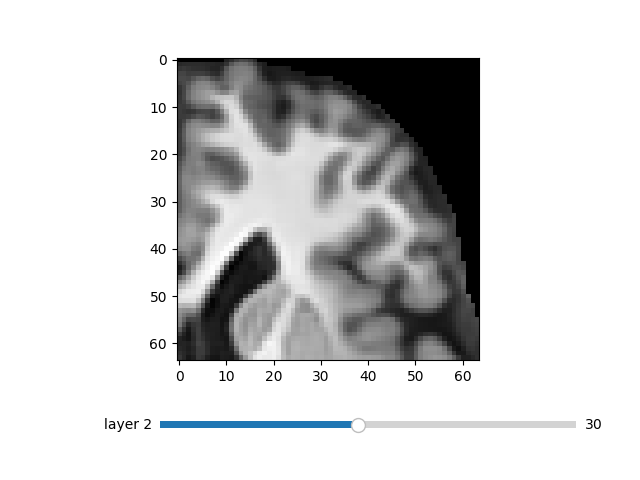

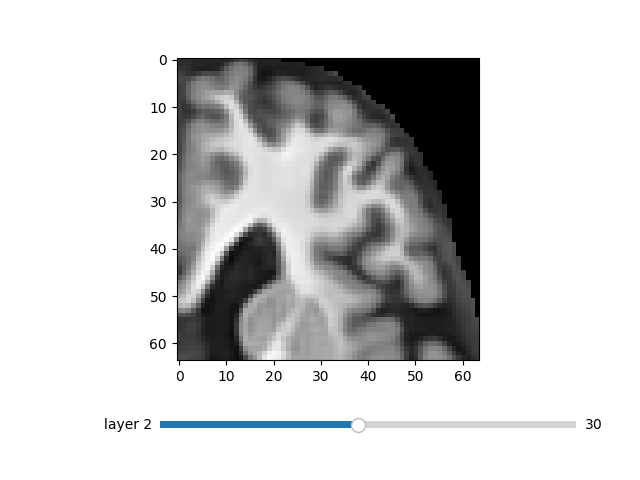

In [7]:
batch_size = 10
image_size = (193,229,193)
patch_size = (64,64,64)
patch_step = (32,32,32)
background_th = 0.1

data_train = DataLoaderPatches(pil.INAME_PREPROCESSED, 
                               batch_size, 
                               image_size, 
                               patch_size, 
                               patch_step, 
                               images_onmemory=3, 
                               shuffle_patches=True, 
                               channels_first=False, 
                               background_th = background_th,
                                shuffle_images=False, 
                                nb_patients=-1, 
                                shuffle_before_selecting=False, 
                                server=False)

first_patches_h3, first_patches_h4  = data_train[0]


fc.imgshow_3D("",first_patches_h3[0,...,0], current_plane=30)
fc.imgshow_3D("",first_patches_h4[0,...,0], current_plane=30)



# print(len(data_train))
# print(data_train.nb_patches)
# while True:
#     print(f"current_index_batch_images: {data_train.current_index_batch_images} / {len(data_train.ids_loader)}")
#     for i, (img_hunt3, img_hunt4) in enumerate(data_train):
#         pass
#         print(f"batch: {i}", )
#         print(img_hunt3.shape)
#         print(img_hunt4.shape)

# print(data_train[-1][0].shape)



# print(data_train.patient_ids)
# data_train.patient_ids.sort()
# print(data_train.patient_ids)
# print(len(data_train.patient_ids))
    


